In [6]:
# Importação das bibliotecas e definição de funções cruciais
import numpy as np
import matplotlib.pyplot as plt
from tifffile import TiffFile
from numpy.lib.stride_tricks import sliding_window_view # usado na análise da entropia conjunta

testing_file = "../dev.tiff"
verbose = False
def entropia(counts):
    p = counts[counts>0] / counts.sum()
    return -np.sum(p*np.log2(p))

def countOcurrences(arr):
    return np.unique(arr, return_counts=True)

def loadImages(filename):
    with TiffFile(filename) as t:
        return [p.asarray() for p in t.pages]
images = loadImages(testing_file)
def bar_graph_with_mean(x, y, figsize=(11,4), title="bar graph with mean", ylabel="Dados no y", xlabel="Dados no x"):
    plt.figure(figsize=figsize)
    plt.bar(x, y, color="tab:blue")
    plt.title(title)
    media = y.mean()
    plt.axhline(media, color="red", ls="--", label=f"média de y: {media:06.3f}")
    plt.ylabel(ylabel)
    plt.xlabel(xlabel)
    plt.legend()
    plt.xticks(x)
    plt.tight_layout()
    plt.show()

# Extração de metadados das imagens
O programa `divider.c` está a armazenar os seguintes dados sobre cada imagem:
- **Largura** (`ImageWidth`, uint32)
- **Altura** (`ImageLength`, uint32)
- **Bits por amostra** (`BitsPerSample`, uint16, valor por defeito se ausente)
- **Amostras por píxel** (`SamplesPerPixel`, uint16, valor por defeito se ausente)
- **Compressão** (`Compression`, uint16, valor por defeito se ausente)
- **Configuração planar** (`PlanarConfig`, uint16, valor por defeito se ausente)
- **Linhas por strip** (`RowsPerStrip`, uint32, valor por defeito se ausente)
- **Interpretação das cores** (`Photometric`, uint16, `PHOTOMETRIC_MINISBLACK` se ausente)
- **Dados dos píxeis**: lidos strip a strip já descomprimidos e escritos de novo com a compressão da origem

Estes dados são importantes para conclusões quanto ao que analisar do conteúdo de cada página/imagem. Para isso o seguinte script foi desenvolvido.

## Metadados das páginas

- **pagina**: índice da página dentro do ficheiro TIFF, começando em 0.
- **largura**: número de colunas de píxeis da imagem (`ImageWidth`).
- **altura**: número de linhas de píxeis da imagem (`ImageLength`).
- **area**: largura × altura, ou seja, o número total de píxeis da página.
- **bits**: número de bits usados para guardar cada valor de cada sample (`BitsPerSample`), ou seja, *quantização*. Por exemplo, 8 para escala de cinzentos típica, 16 para imagens de maior profundidade.
- **samples**: número de valores por píxel (`SamplesPerPixel`). 1 para escala de cinzentos, 3 para RGB, 4 para RGBA ou CMYK.
- **compressao**: algoritmo usado para comprimir os dados da imagem (`Compression`). Por exemplo, `NONE` (sem compressão), `LZW`, `DEFLATE` ou `JPEG`.
- **planar**: forma como os samples de cada píxel são organizados (`PlanarConfiguration`). `CONTIG` (1) guarda os valores de cada píxel juntos, e `SEPARATE` (2) guarda todos os valores de um canal antes do seguinte. Só tem efeito quando `samples > 1`.
- **rows_per_strip**: número de linhas agrupadas numa strip, a unidade de compressão e de leitura do TIFF (`RowsPerStrip`).
- **photometric**: interpretação dos valores dos píxeis (`PhotometricInterpretation`). Por exemplo, `MINISBLACK` (0 é preto), `WHITEISZERO` (0 é branco), `RGB`, `PALETTE` (valor é índice numa tabela de cores) ou `CMYK`.
    

In [2]:
def _nome(valor):
    # Enums do tifffile (COMPRESSION, PHOTOMETRIC, PLANARCONFIG) -> texto
    return getattr(valor, "name", str(valor))


def metadados(filename):
    """Lê só as tags de cada página (sem decodificar píxeis) e devolve arrays numpy."""
    with TiffFile(filename) as t:
        paginas = list(t.pages)

    largura = np.array([p.imagewidth for p in paginas], dtype=np.int64)
    altura = np.array([p.imagelength for p in paginas], dtype=np.int64)

    return {
        "pagina": np.arange(len(paginas)),
        "largura": largura,
        "altura": altura,
        "area": largura * altura,
        "bits": np.array([p.bitspersample for p in paginas], dtype=np.int64),
        "samples": np.array([p.samplesperpixel for p in paginas], dtype=np.int64),
        "compressao": np.array([_nome(p.compression) for p in paginas]),
        "planar": np.array([_nome(p.planarconfig) for p in paginas]),
        "rows_per_strip": np.array([p.rowsperstrip for p in paginas], dtype=np.int64),
        "photometric": np.array([_nome(p.photometric) for p in paginas]),
    }


def resumo(meta):
    """Percorre todos os campos existentes em meta. np.unique só devolve valores
    que aparecem, por isso nunca se listam ocorrências de 0, e novos campos
    entram no resumo automaticamente."""
    total = meta["pagina"].size
    print(f"Total de páginas: {total}")

    for campo, dados in meta.items():
        if campo == "pagina":
            continue
        valores, n = np.unique(dados, return_counts=True)
        print(f"\n{campo}: {valores.size} valor(es) distinto(s)")
        for v, c in zip(valores.tolist(), n.tolist()):
            print(f"  {v}: {c} página(s) ({100 * c / total:.1f}%)")


def barras(ax, meta, campo):
    valores, n = np.unique(meta[campo], return_counts=True)
    b = ax.bar(valores.astype(str), n, color="tab:blue")
    ax.bar_label(b, fontsize=8)
    ax.set_title(campo)
    ax.set_ylabel("nº de páginas")
    ax.tick_params(axis="x", rotation=45)


def graficos(meta):
    campos = [k for k in meta if k != "pagina"]
    colunas = 3
    linhas = -(-len(campos) // colunas)  # arredondamento para cima
    fig, eixos = plt.subplots(linhas, colunas, figsize=(17, 5 * linhas))
    eixos = np.atleast_1d(eixos).flatten()

    for ax, campo in zip(eixos, campos):
        barras(ax, meta, campo)
    for ax in eixos[len(campos):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Total de páginas: 32

largura: 2 valor(es) distinto(s)
  512: 22 página(s) (68.8%)
  1024: 10 página(s) (31.2%)

altura: 2 valor(es) distinto(s)
  512: 22 página(s) (68.8%)
  1024: 10 página(s) (31.2%)

area: 2 valor(es) distinto(s)
  262144: 22 página(s) (68.8%)
  1048576: 10 página(s) (31.2%)

bits: 1 valor(es) distinto(s)
  8: 32 página(s) (100.0%)

samples: 1 valor(es) distinto(s)
  1: 32 página(s) (100.0%)

compressao: 1 valor(es) distinto(s)
  NONE: 32 página(s) (100.0%)

planar: 1 valor(es) distinto(s)
  CONTIG: 32 página(s) (100.0%)

rows_per_strip: 2 valor(es) distinto(s)
  8: 10 página(s) (31.2%)
  16: 22 página(s) (68.8%)

photometric: 1 valor(es) distinto(s)
  MINISBLACK: 32 página(s) (100.0%)


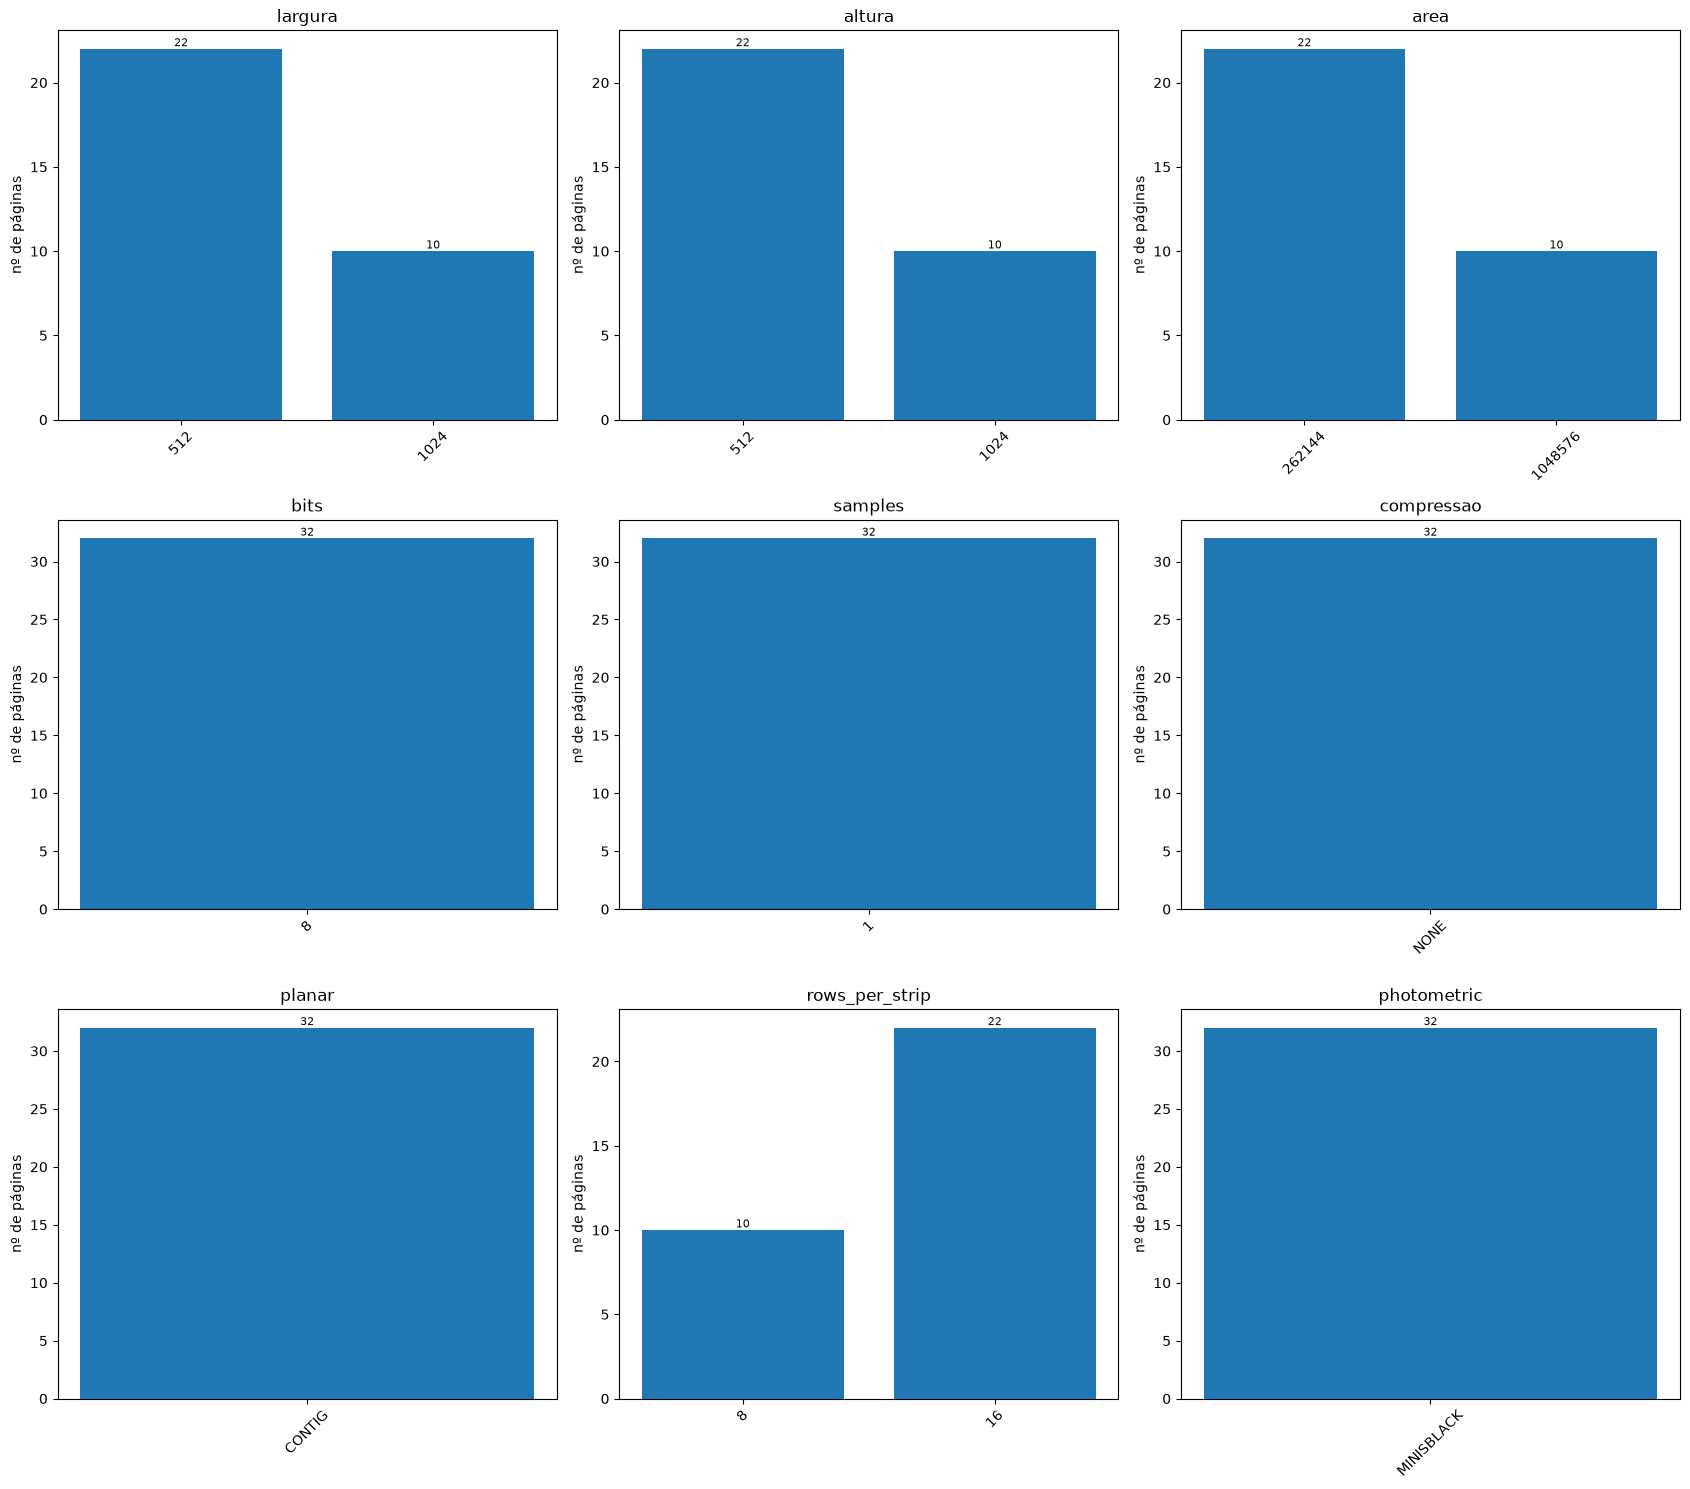

In [117]:
# ---- Execução ----
meta = metadados(testing_file)
resumo(meta)
graficos(meta)

# Conclusões sobre metadados

Os metadados disponíveis para cada imagem ajudam a concluir o tipo de fonte que o codec irá tratar e comprimir. Características homólogas entre as imagens:
 - **Quantização**: 8 bits
 - **Canais por cor**: 1 -> imagem em escala de cinzentos, um valor por píxel, sendo indiferente o metadado a seguir
 - **Maneira de armazenamento para mais de 1 canal de cor**: CONTIG -> forma contígua, ou seja, para uma imagem RGB é armazenada como R G B, R G B, R G B. Armazenada a informação de 1 pixel toda junta e não separadamente (primeiro só R, depois só G, e por fim só B)
 - **Linhas por Strip**: 8 ou 16 -> usa 8 ou 16 linhas por cada strip (ver documentação acima para esclarecimentos)
 - **Fótometria**: MINISBLACK -> menor valor do píxel é preto (0 é preto e 255 é branco)

Conclui-se que a fonte serão imagens a preto e branco com 8 bits de quantização com 1 canal de cor e em que 0 é preto e 255 é branco

## Byte ou Bit?

É importante averiguar se a análise é feita ao nível do bit ou do byte, sendo o byte um agrupamento de 8 bits. Pela regra da cadeia, a entropia do byte pode ser decomposta na soma das entropias condicionais dos seus bits:

$$
H(X) = \sum_{k=0}^{7} H(B_k \mid B_{k+1}, \dots, B_7)
$$

Esta igualdade é sempre válida. Só nos casos em que os bits são independentes é que a decomposição se reduz a

$$
H(X) = \sum_{k=0}^{7} H(B_k) \qquad \text{(apenas se os bits forem independentes)}
$$

Em geral, $\sum_{k} H(B_k) \geq H(X)$, com igualdade só para bits independentes. Nas imagens, os bits do mesmo píxel e de píxeis vizinhos não são independentes; por isso, analisar os planos isoladamente, sem contexto, sobreestima a entropia.

## Conclusão

A análise deve ser feita ao nível do byte, com o píxel de 8 bits como símbolo, e não ao nível do bit, porque os bits do mesmo píxel não são independentes. A decomposição em planos só compensa com um modelo de contexto próprio para cada plano.

O que pode reduzir a entropia é o contexto. Como condicionar nunca aumenta a entropia, $H(X_n \mid X_1, \dots, X_{n-1}) \le H(X_n \mid X_1, \dots, X_{n-2})$. Com contextos grandes, o número de combinações cresce muito mais depressa do que o número de píxeis, e a entropia estimada fica enviesada para baixo.

Por isso, o tamanho do contexto deve ser escolhido com medições, não apenas teoricamente. Os resultados do notebook são fiáveis até $n = 3$, pelo que é aí que se deve avaliar a redução.

# Estudo da Entropia

O estudo da entropia baseia-se apenas nos valores de teste do ficheiro `dev.tiff`. Como foi concluído na secção "Conclusão", o contexto deve ser escolhido com medições e não com valores puramente teóricos, que neste caso seriam apenas suposições. Este estudo pretende determinar um critério para o contexto, consoante os dados da fonte.

Considera-se que cada $X_i$ é um byte (um píxel de 8 bits) numa sequência. A ordem da entropia indica quantos bytes entram na estimativa, incluindo o byte a codificar:

- Entropia de 1.ª ordem: $H(X_1)$, sem contexto
- Entropia de 2.ª ordem: $H(X_2 \mid X_1)$, com 1 byte de contexto
- Entropia de 3.ª ordem: $H(X_3 \mid X_1, X_2)$, com 2 bytes de contexto
- ...

Pela regra da cadeia, $H(X_1, \dots, X_n)$ é a soma das entropias de ordem $1$ a $n$. Por isso, acrescentar contexto nunca aumenta a entropia verdadeira.

O aumento dos blocos (extensões de ordem $n$ da fonte) permite aproximar o comprimento médio do limite teórico, mas tem um custo computacional elevado, porque o alfabeto cresce exponencialmente com $n$.

Seja $\bar{l}_n$ o comprimento médio, por bloco, de um código de Huffman ou de Shannon aplicado aos blocos de $n$ símbolos. Então

$$
H(X^n) \le \bar{l}_n < H(X^n) + 1.
$$

Como o comprimento médio por símbolo é $\bar{l}_n / n$, obtém-se

$$
\frac{H(X^n)}{n} \le \frac{\bar{l}_n}{n} < \frac{H(X^n)}{n} + \frac{1}{n}.
$$

Ao aumentar $n$, o termo $\frac{1}{n}$ tende para zero, pelo que $\frac{\bar{l}_n}{n}$ tende para a taxa de entropia da fonte, $\lim_{n\to\infty} \frac{H(X^n)}{n}$. Para uma fonte i.i.d., esta taxa é $H(X)$. Os píxeis de uma imagem têm dependência, por isso a taxa é, em geral, menor que $H(X)$.

Seja $\mathcal{X}$ um alfabeto de cardinalidade $D$. A extensão de ordem $n$ tem alfabeto

$$
\mathcal{X}^n = \{(x_1, \dots, x_n) : x_i \in \mathcal{X}\}, \qquad |\mathcal{X}^n| = D^n.
$$

Com $D = 256$ (píxeis de 8 bits, que é o nosso caso), $n = 2$ dá $65\,536$ símbolos e $n = 3$ dá cerca de $1{,}7 \times 10^7$. Com uma amostra finita, as probabilidades de blocos tão grandes ficam pouco fiáveis. Os resultados do notebook só são fiáveis até $n = 3$.

Conclui-se que aumentar exageradamente a ordem $n$ prejudica o codec sobretudo em memória e tempo de cálculo, e que a ordem deve ser escolhida medindo a redução de $H(X_n \mid X_1, \dots, X_{n-1})$ no `dev.tiff`, até ao ponto em que a estimativa ainda é fiável.

## Todas as imagens do dev.tiff numa só figura
Apenas para ver quais imagens estão a ser analisadas

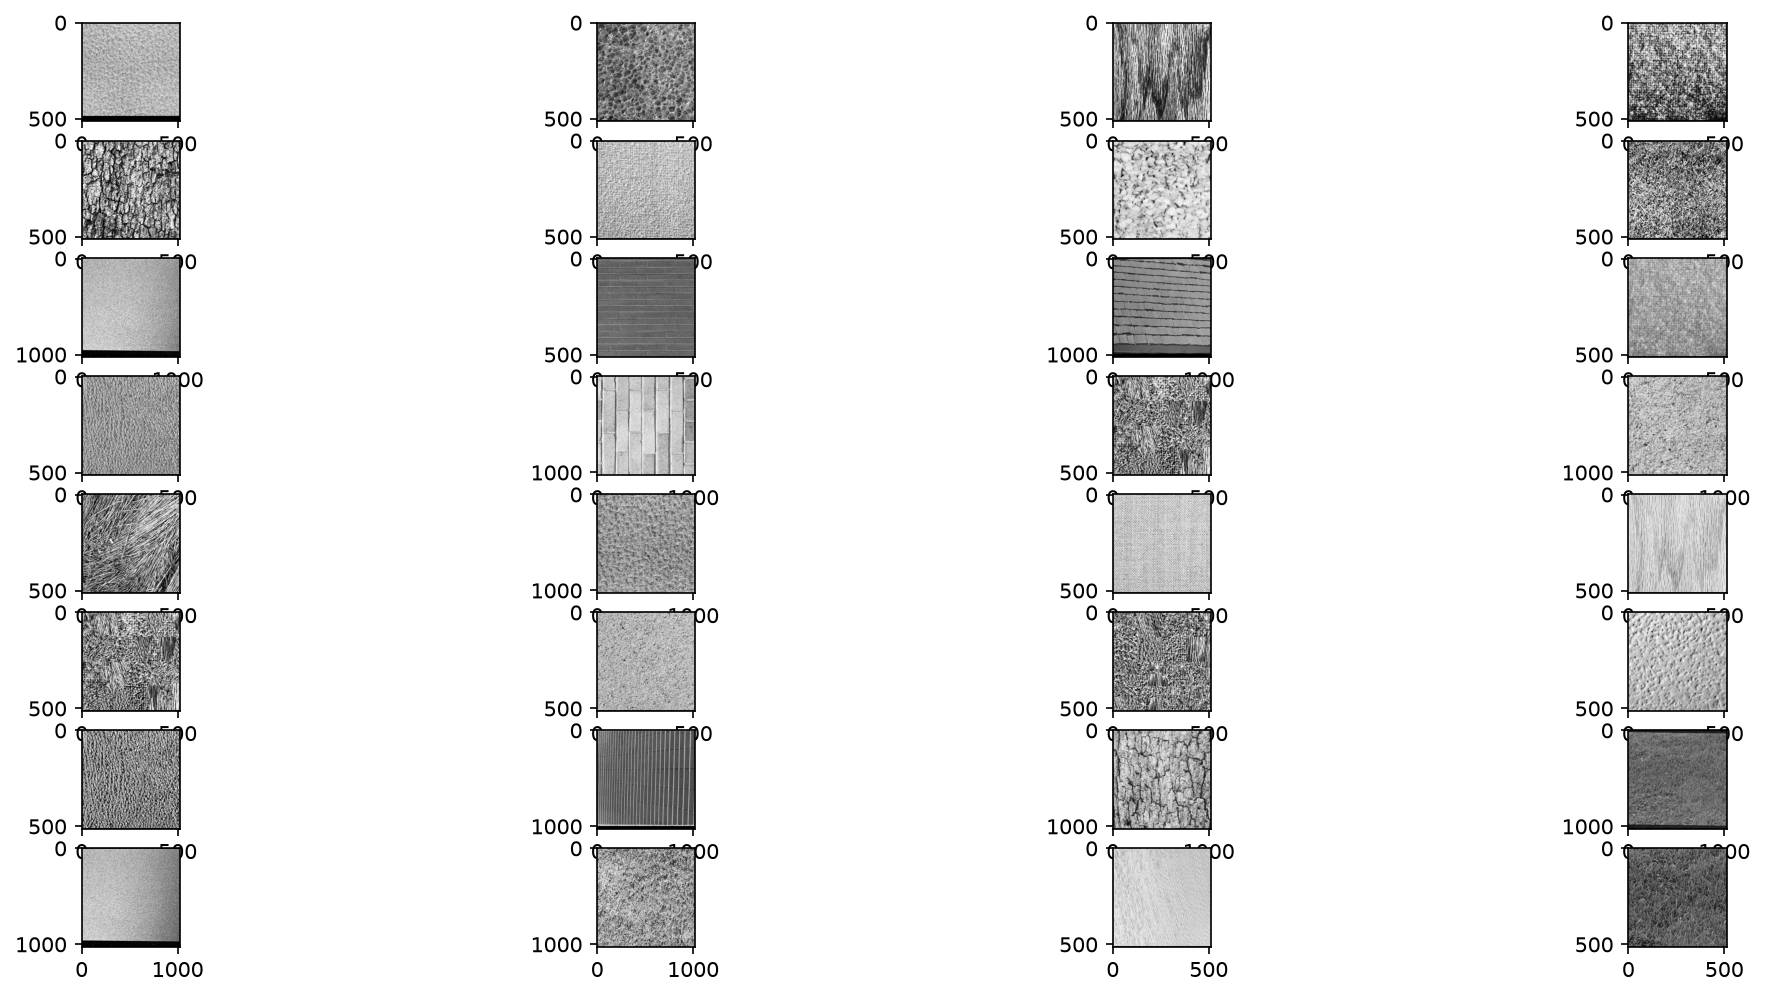

In [119]:
rows = len(images) // 4
cols = len(images) // rows
figs, axis = plt.subplots(rows, cols, figsize=(17,8), dpi=150)
axis = axis.flatten()

for i, img in enumerate(images):
    axis[i].imshow(img, cmap="gray")

plt.show()

# Análise dos dados das imagens

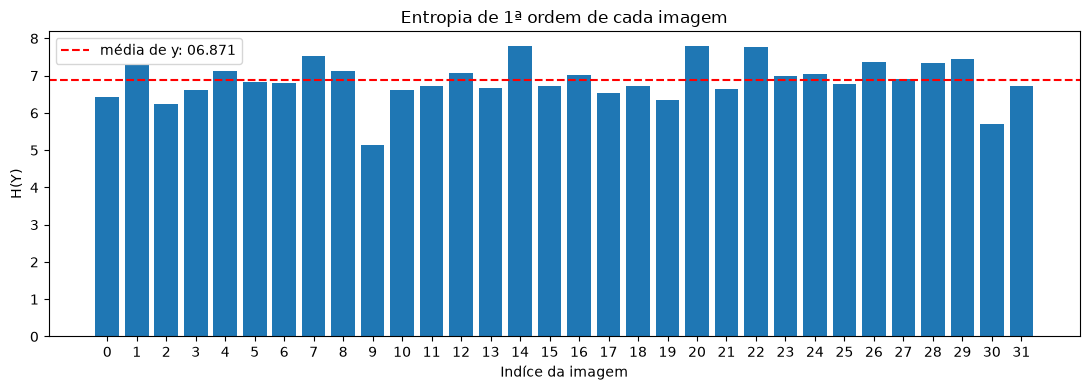

-----------------------------------
Entropia média das páginas: 6.8715 bits


In [139]:
entropias_individuais = np.array([])
pages = []
for i, img in enumerate(images):
    # np.unique com return_counts=True dá diretamente as ocorrências de cada valor de pixel
    values, counts = countOcurrences(img)
    h = entropia(counts)
    entropias_individuais = np.append(entropias_individuais, h)
    pages.append(i)
    if verbose:
        print(f"Página {i:02d}: {h:.4f} bits")
bar_graph_with_mean(
    pages,
    entropias_individuais,
    figsize=(11,4),
    title="Entropia de 1ª ordem de cada imagem",
    xlabel="Indíce da imagem",
    ylabel="H(Y)"    
)
print("-" * 35)
print(f"Entropia média das páginas: {np.mean(entropias_individuais):.4f} bits")

In [140]:
def chaves_blocos(img, n):
    """Transforma cada bloco de n píxeis consecutivos (na mesma linha) num número único.
    Isto serve só para conseguir contar quantas vezes cada bloco aparece."""
    img = img.astype(np.uint64)
    # nj = nº de janelas (blocos) possíveis por linha.
    # Numa linha de W píxeis, cabem W - n + 1 blocos de tamanho n.
    # Os blocos nunca passam para a linha seguinte.
    nj = img.shape[1] - n + 1
    # Matriz que vai guardar a chave de cada bloco: uma linha por linha da imagem,
    # uma coluna por janela. Começa a zeros.
    chave = np.zeros((img.shape[0], nj), dtype=np.uint64)
    # Constrói a chave "dígito a dígito", como se escreve um número em base 256.
    # Na volta k, junta o k-ésimo píxel de todas as janelas ao mesmo tempo:
    #   img[:, k:k + nj] é a imagem deslocada k colunas para a esquerda,
    #   por isso a coluna j desta fatia é o píxel k do bloco que começa na coluna j.
    # chave * 256 "empurra" os dígitos anteriores para a esquerda e soma o novo.
    for k in range(n):
        chave = (chave * 256) + img[:, k:k + nj] ## o * 256 é essencialmente << 8. Isto condiciona os agrupamentos.
    
    return chave.ravel() # Transforma a matriz num vetor duma dimensão: uma chave por bloco.

In [12]:
## Entropia conjunta de blocos de n símbolos

def chaves_blocos(img, n):
    """Transforma cada bloco de n píxeis consecutivos (na mesma linha) num número único.
    Isto serve só para conseguir contar quantas vezes cada bloco aparece."""
    img = img.astype(np.uint64)
    # nj = nº de janelas (blocos) possíveis por linha.
    # Numa linha de W píxeis, cabem W - n + 1 blocos de tamanho n.
    # Os blocos nunca passam para a linha seguinte.
    nj = img.shape[1] - n + 1
    # Matriz que vai guardar a chave de cada bloco: uma linha por linha da imagem,
    # uma coluna por janela. Começa a zeros.
    chave = np.zeros((img.shape[0], nj), dtype=np.uint64)
    # Constrói a chave "dígito a dígito", como se escreve um número em base 256.
    # Na volta k, junta o k-ésimo píxel de todas as janelas ao mesmo tempo:
    #   img[:, k:k + nj] é a imagem deslocada k colunas para a esquerda,
    #   por isso a coluna j desta fatia é o píxel k do bloco que começa na coluna j.
    # chave * 256 "empurra" os dígitos anteriores para a esquerda e soma o novo.
    for k in range(n):
        chave = (chave * 256) + img[:, k:k + nj] ## o * 256 é essencialmente << 8. Isto condiciona os agrupamentos.
    
    return chave.ravel() # Transforma a matriz num vetor duma dimensão: uma chave por bloco.

def entropia_blocos(img, n):
    """Calcula a entropia conjunta H(X1..Xn) de blocos de n píxeis,
    juntando os blocos de todas as imagens da lista imgs."""    
    chaves = chave_blocos(img, n)
    if verbose:
        print(f"Chaves: {chaves}\nFigura: {chaves.shape}")
    _, counts = np.unique(chaves, return_counts=True, axis=0) ## o axis=0 é que vai fazer a contagem dos blocos agrupados
    # Devolve 3 coisas:
    #1) a entropia dos blocos, H(X1..Xn), em bits por bloco
    #(a função entropia() transforma as contagens em probabilidades e aplica -soma(p * log2(p)));
    #2) len(chaves): nº total de blocos observados (amostras);
    #3) len(counts): nº de blocos distintos. Se for próximo das amostras,
    #quase todos os blocos aparecem uma só vez e a entropia fica
    #artificialmente baixa (resultado pouco fiável).
    return entropia(counts)/n, len(chaves), len(counts)

Entropia conjunta de cada Página/imagem


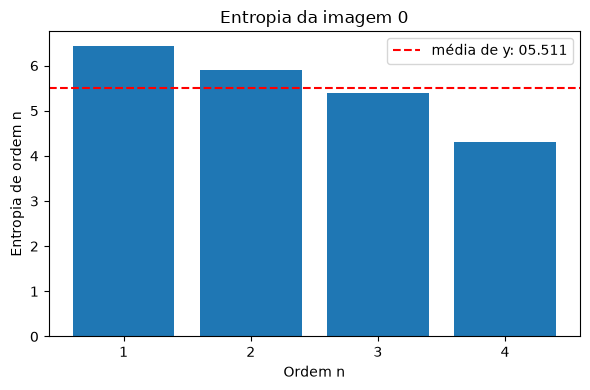

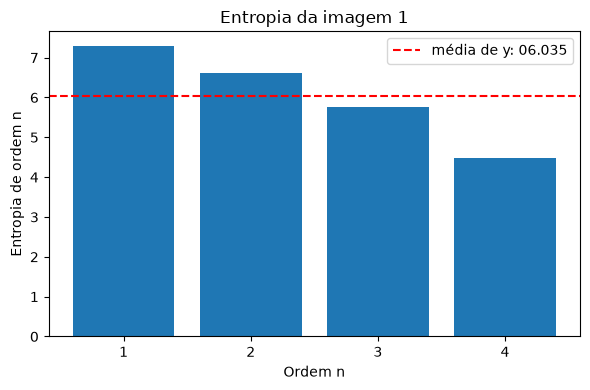

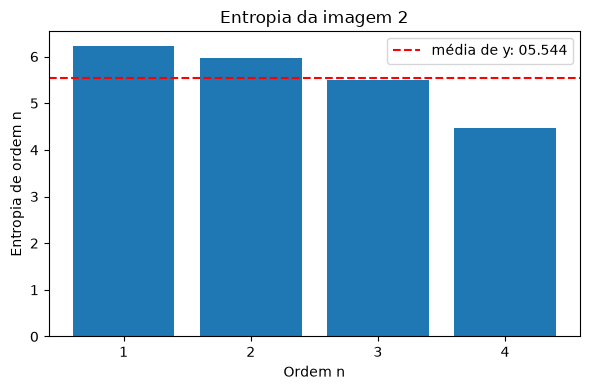

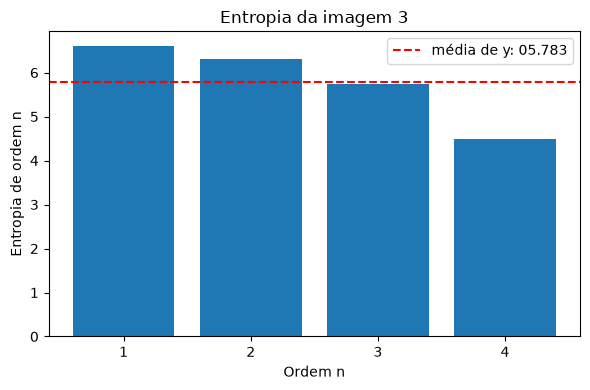

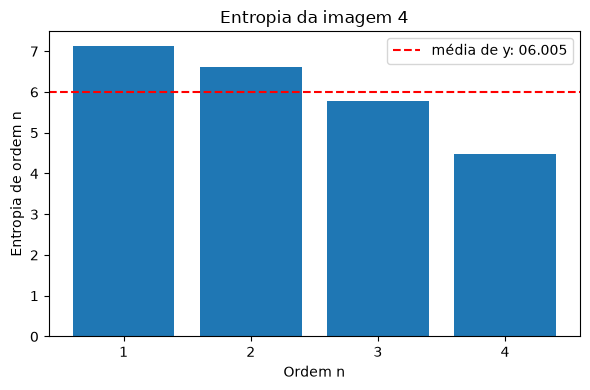

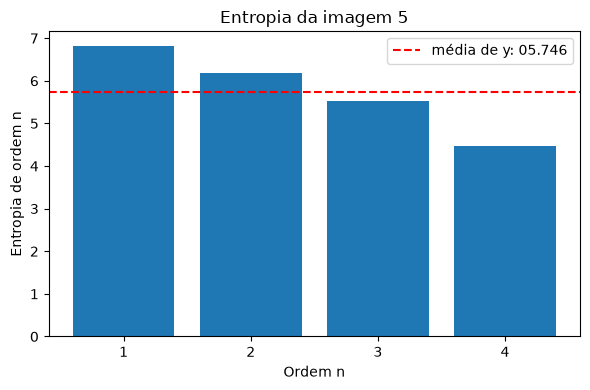

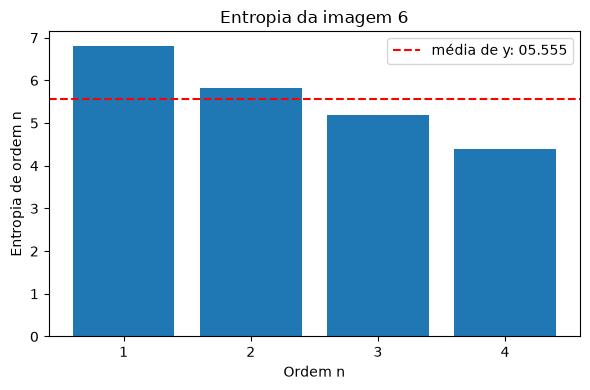

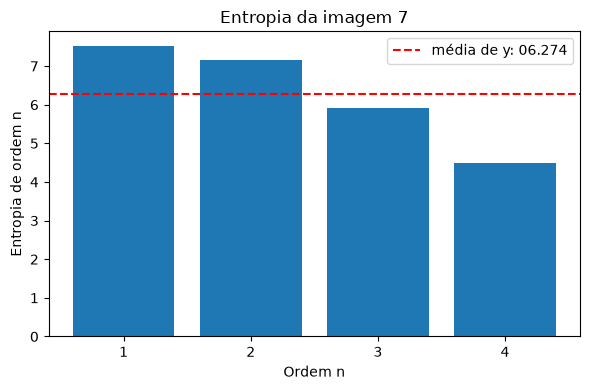

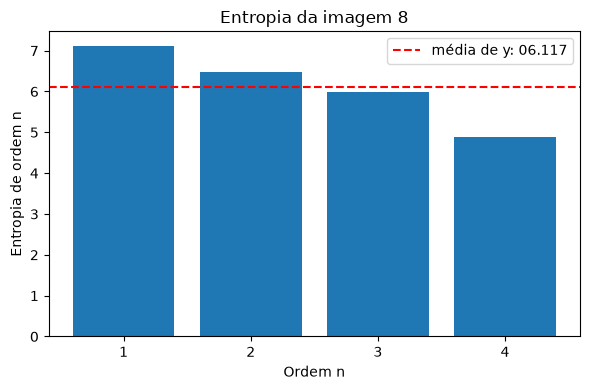

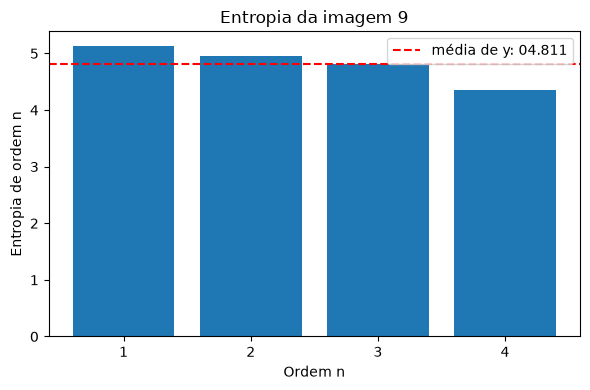

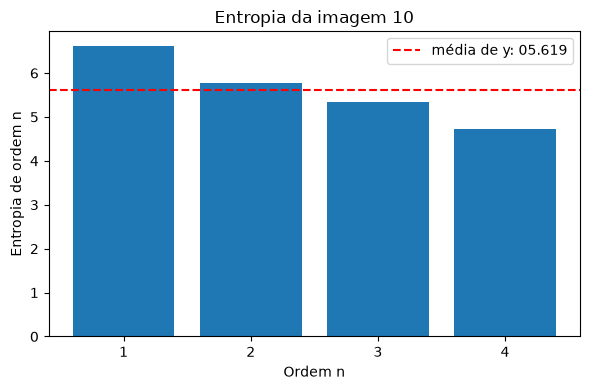

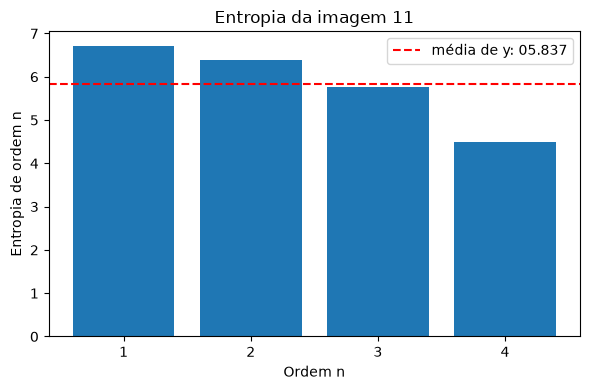

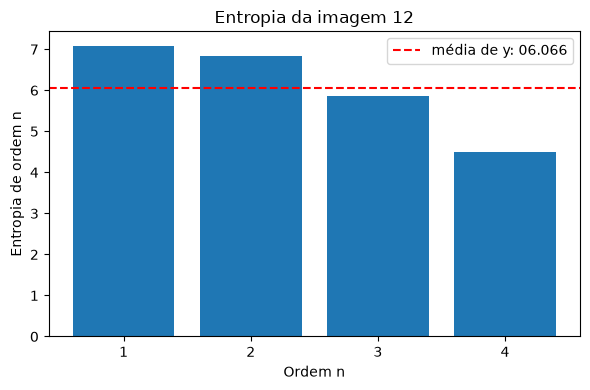

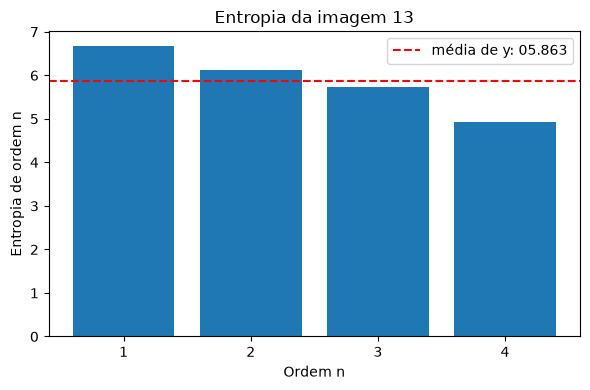

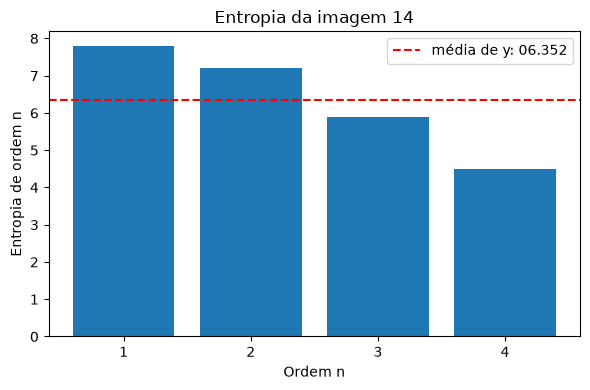

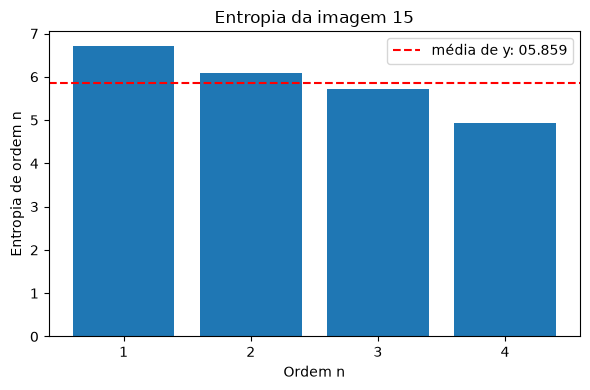

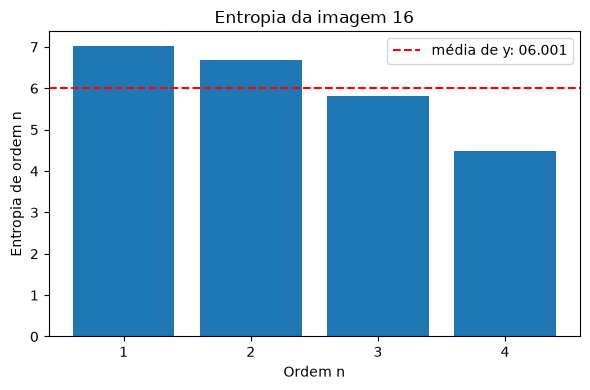

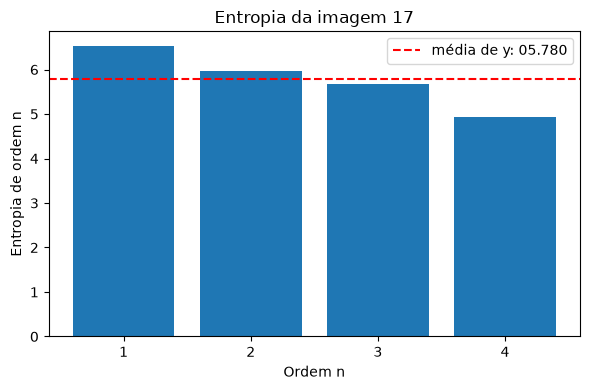

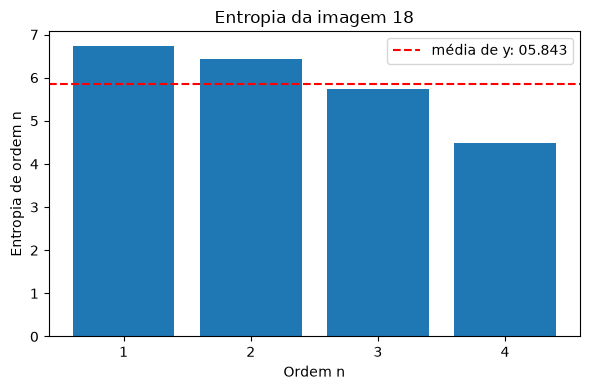

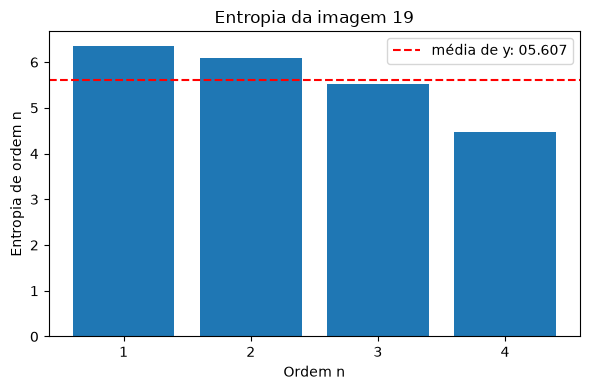

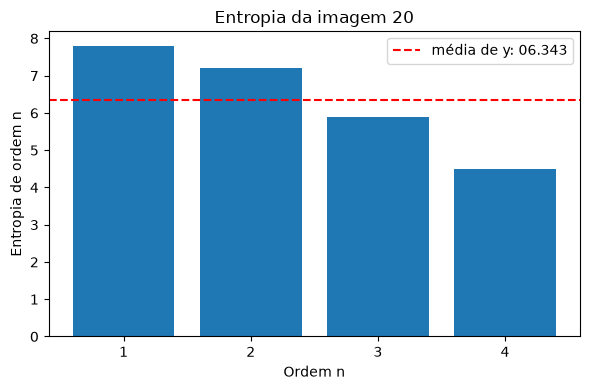

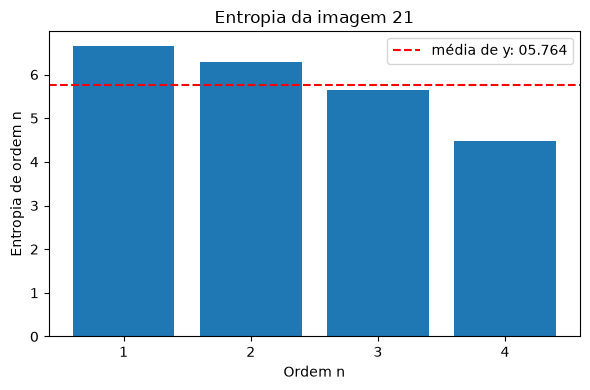

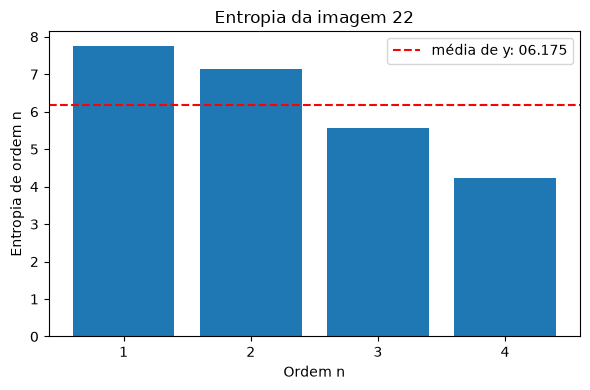

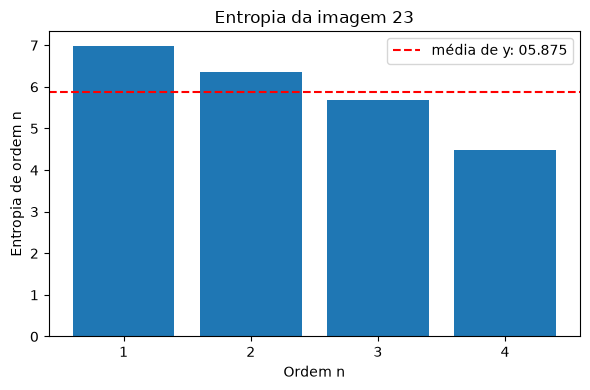

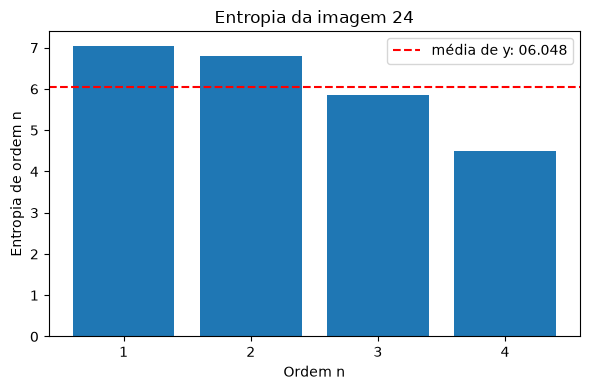

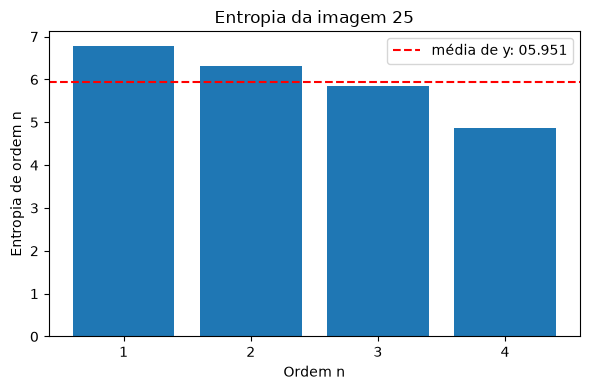

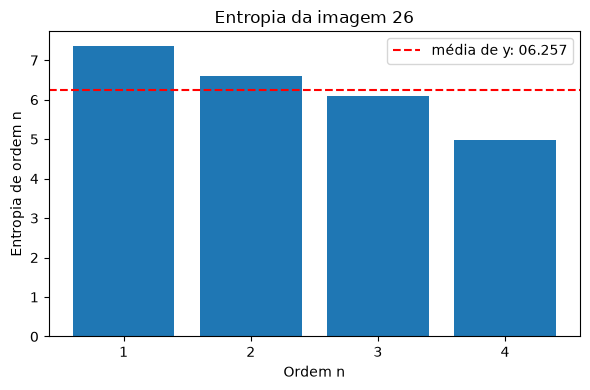

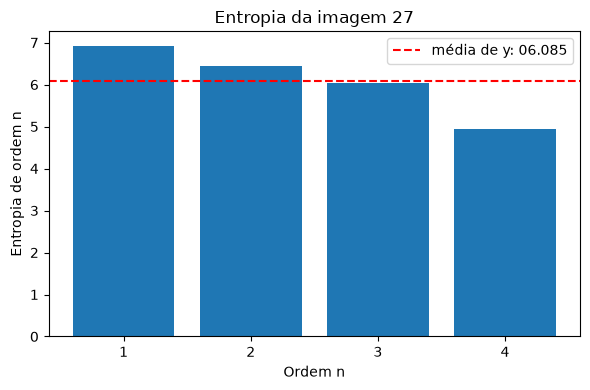

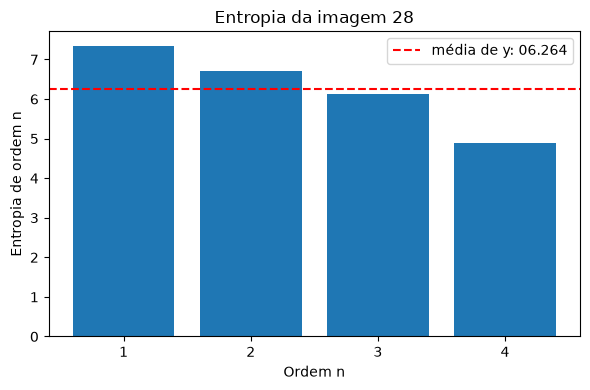

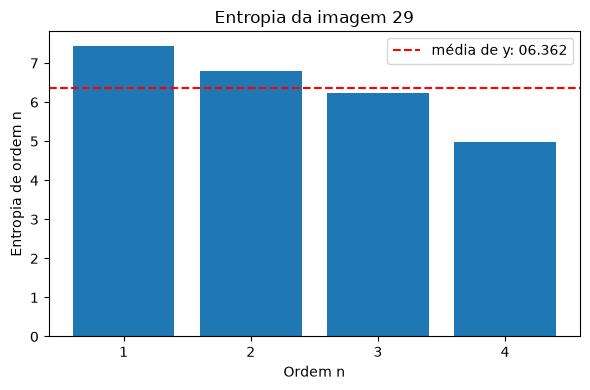

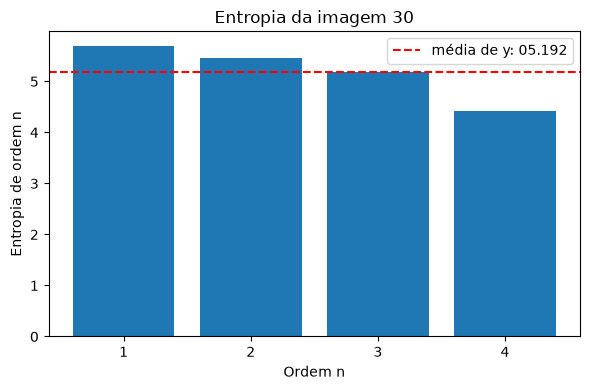

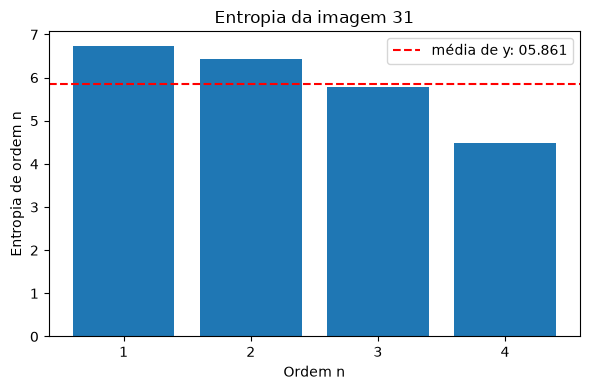

In [13]:
N_MAX = 4
print("Entropia conjunta de cada Página/imagem")
for i, img in enumerate(images):
    # Para cada n, calcula a entropia do bloco só desta imagem
    # ([img] = lista com uma só imagem; [0] = só a entropia, ignora os outros 2 valores)
    # e divide por n para ficar em bits por píxel.
    vals = [(n, entropia_blocos(img, n)) for n in range(1, N_MAX + 1)]
    bar_graph_with_mean(
        np.array([vals[i][0] for i in range(len(vals))]), ## valores de n
        np.array([vals[i][1][0] for i in range(len(vals))]), ## entropia para agrupamento a n
        title=f"Entropia da imagem {i}",
        xlabel="Ordem n",
        ylabel="Entropia de ordem n",
        figsize=(6, 4)
    )
    if verbose:
        print(f"Página {i:02d}: \n\t" + " \n\t ".join(f"n={n}: {v[0]/n:.4f}" for n, v in enumerate(vals, 1)))

# Análise com códigos preditivos

In [11]:
#  Fig. 2 e 3  dependência entre píxeis vizinhos
#  Fig. 4 a 6  predição
#  Fig. 7      histograma dos píxeis vs histograma dos resíduos
#  Fig. 8      que tipo de algoritmo compensa (dispersão)
NOMES = {0: "0: sem pred.", 1: "1: A", 2: "2: B", 3: "3: C", 4: "4: A+B-C",
         5: "5: A+(B-C)/2", 6: "6: B+(A-C)/2", 7: "7: (A+B)/2"}

def residuos(img, modo):
    # A = esquerda, B = cima, C = diagonal, X = píxel atual (modos do JPEG Lossless)
    img = img.astype(np.int64)
    A = img[1:, :-1]
    B = img[:-1, 1:]
    C = img[:-1, :-1]
    X = img[1:, 1:]
    pred = {
            0: 0*X, ## devolve só zeros para indicar que não tem predição
            1: A,  ## resíduo com o pixel anterior: a_{n} - a_{n-1}
            2: B,  ## resíduo com o pixel de cima, analisa a imagem na vertical.
            3: C,  ## 
            4: A+B-C,
            5: A+((B-C)>>1), ## >> 1 é o mesmo que dividir por 2
            6: B+((A-C)>>1),
            7: (A+B)>>1
        }[modo]
    return (X - pred).ravel()

def H_valores(v):
    return entropia(np.unique(v, return_counts=True)[1])

paginas = np.arange(len(images))

# ---- Cálculos (por página) ----
H1 = np.array([entropia_blocos([im], 1)[0] for im in images])      # H(X)
H2 = np.array([entropia_blocos([im], 2)[0] for im in images])      # H(X1,X2) = H(X1) + H(X2|X1)
Hcond = H2 - H1                                                     # H(X2|X1) = H(X1, X2) - H(X1)
Imut = H1 - Hcond                                                   # I(X1;X2) = H(X1) - H(X2|X1) = H(X1) + H(X2) - H(X1, X2)
# Hpred[página][modo] = entropia dos resíduos de cada modo de predição (modo 0 = sem predição)
Hpred = np.array([[H_valores(residuos(im, m)) for m in range(8)] for im in images])
Hmelhor = Hpred[:, 1:].min(axis=1)
melhor_modo = Hpred[:, 1:].argmin(axis=1) + 1

In [9]:
# ---- Gráfico 2: dependência entre píxeis vizinhos ----
# Se a 2ª barra for bem menor que a 1ª, o píxel vizinho ajuda a prever o seguinte.
plt.figure(figsize=(12, 4))
l = 0.38
plt.bar(paginas - l/2, H1, l, label="H(X)  (sem contexto)")
plt.bar(paginas + l/2, Hcond, l, label="H(X2|X1)  (conhecendo o píxel à esquerda)")
plt.xlabel("Página (fonte)"); plt.ylabel("bits/píxel")
plt.title("Dependência entre píxeis vizinhos: o contexto reduz a entropia")
plt.xticks(paginas); plt.legend(); plt.tight_layout(); plt.show()

NameError: name 'paginas' is not defined

<Figure size 1200x400 with 0 Axes>

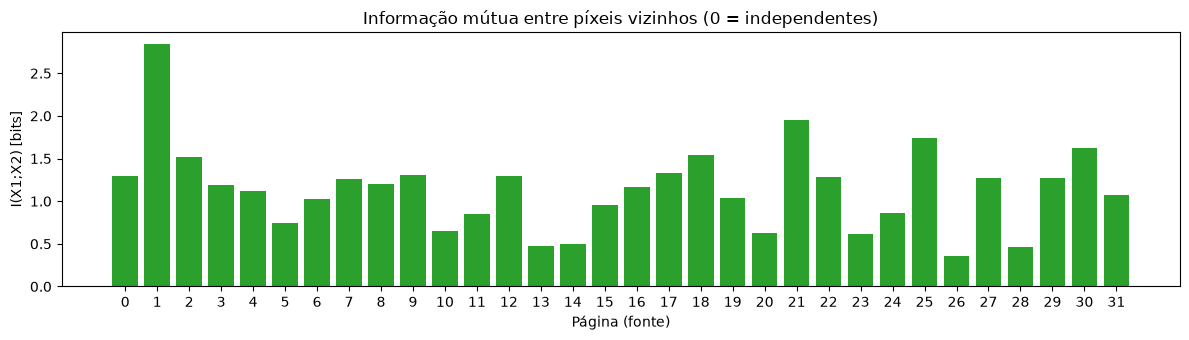

In [14]:
# ---- Gráfico 3: informação mútua entre píxeis vizinhos ----
# Mede a mesma dependência do Gráfico 2 numa só grandeza: I = H(X) - H(X2|X1).
plt.figure(figsize=(12, 3.5))
plt.bar(paginas, Imut, color="tab:green")
plt.xlabel("Página (fonte)"); plt.ylabel("I(X1;X2) [bits]")
plt.title("Informação mútua entre píxeis vizinhos (0 = independentes)")
plt.xticks(paginas); plt.tight_layout(); plt.show()

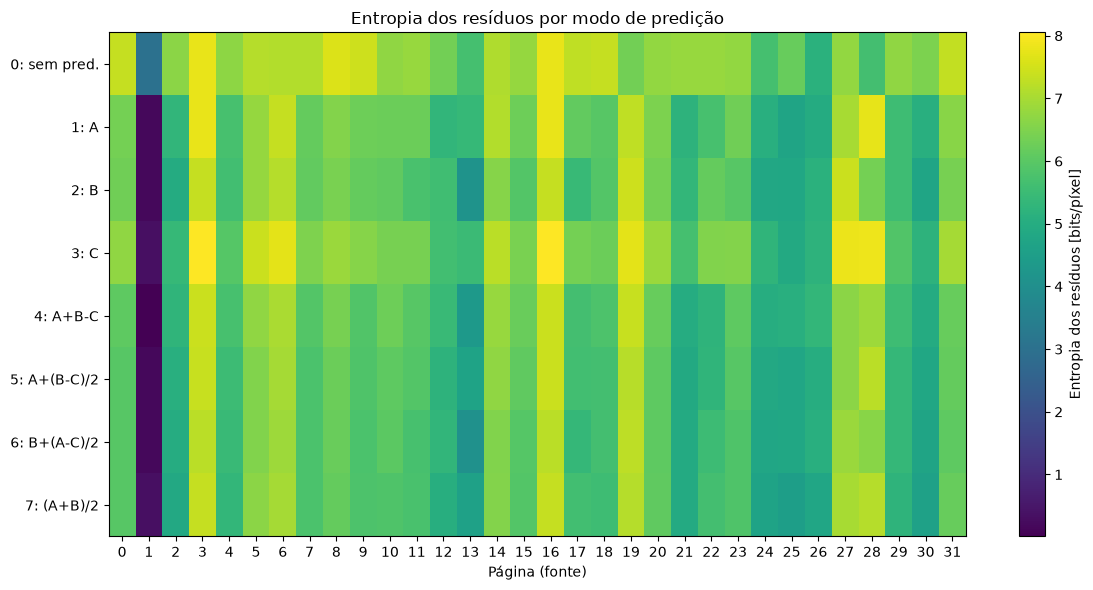

In [15]:
# ---- Gráfico 4: entropia dos resíduos de cada modo de predição (mapa de calor) ----
# Cada coluna é uma página, cada linha um modo. Cores mais escuras = menor entropia = melhor.
plt.figure(figsize=(12, 6))
plt.imshow(Hpred.T, aspect="auto", cmap="viridis")
plt.colorbar(label="Entropia dos resíduos [bits/píxel]")
plt.yticks(range(8), [NOMES[m] for m in range(8)])
plt.xticks(paginas); plt.xlabel("Página (fonte)")
plt.title("Entropia dos resíduos por modo de predição")
plt.tight_layout(); plt.show()

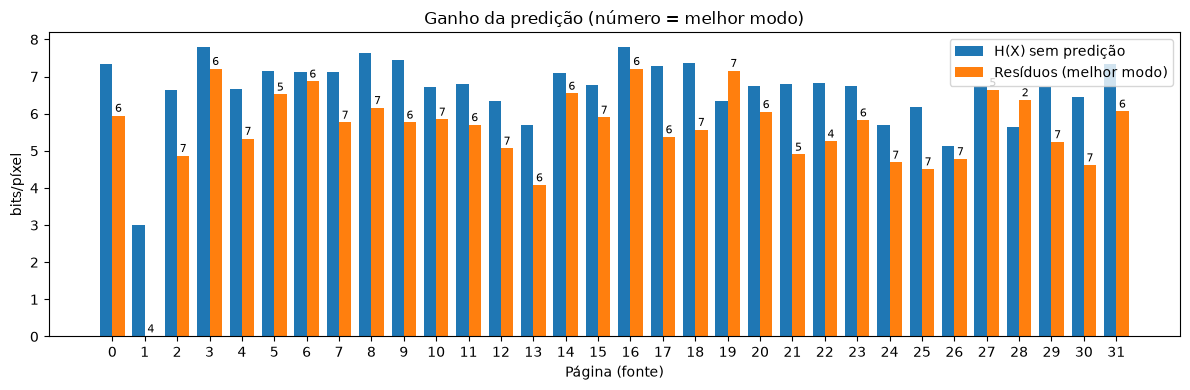

In [18]:
# ---- Gráfico 5: ganho da predição por página ----
# Compara H(X) com a entropia dos resíduos do melhor modo (o número é o modo).
# Se a barra dos resíduos for maior que a de H(X), a predição piora essa página.
plt.figure(figsize=(12, 4))
plt.bar(paginas - l/2, H1, l, label="H(X) sem predição")
plt.bar(paginas + l/2, Hmelhor, l, label="Resíduos (melhor modo)")
for p in paginas:
    plt.text(p + l/2, Hmelhor[p] + 0.1, str(melhor_modo[p]), ha="center", fontsize=8)
plt.xlabel("Página (fonte)"); plt.ylabel("bits/píxel")
plt.title("Ganho da predição (número = melhor modo)")
plt.xticks(paginas); plt.legend(); plt.tight_layout(); plt.show()

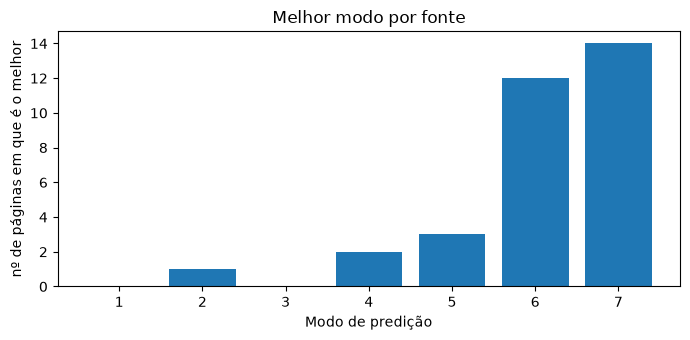

In [19]:
# ---- Gráfico 6: quantas páginas têm cada modo como melhor ----
# Mostra se existe um modo dominante ou se o melhor modo depende da página.
plt.figure(figsize=(7, 3.5))
cont = np.bincount(melhor_modo, minlength=8)[1:]
plt.bar(range(1, 8), cont)
plt.xlabel("Modo de predição"); plt.ylabel("nº de páginas em que é o melhor")
plt.title("Melhor modo por fonte"); plt.tight_layout(); plt.show()

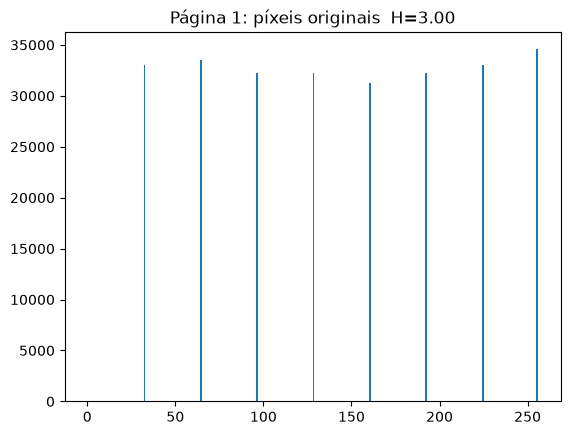

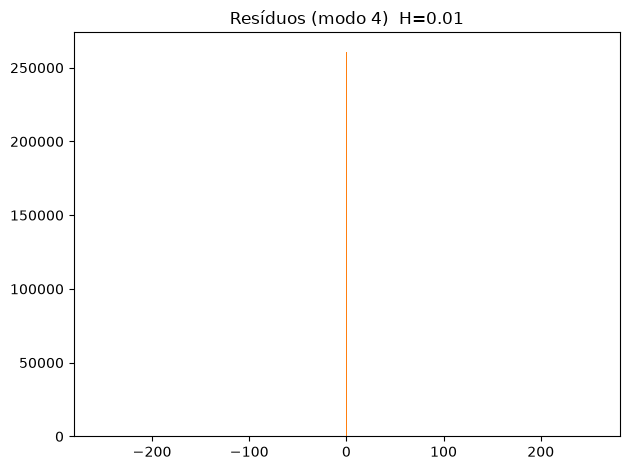

In [28]:
# ---- Gráfico 7: histograma dos píxeis vs histograma dos resíduos ----
# Na página onde a predição mais reduz a entropia. Os resíduos concentram-se perto de 0.
pg = int(np.argmax(H1 - Hmelhor))
img, modo = images[pg], melhor_modo[pg]
res = residuos(img, modo)
plt.figure(1)
plt.hist(img.ravel(), bins=256, range=(0, 256), color="tab:blue")
plt.title(f"Página {pg}: píxeis originais  H={H1[pg]:.2f}")
plt.figure(2)
plt.hist(res, bins=np.arange(-255, 257), color="tab:orange")
plt.title(f"Resíduos (modo {modo})  H={Hmelhor[pg]:.2f}")
for a in ax:
    a.set_xlabel("valor")
    a.set_ylabel("contagem")
plt.tight_layout()
plt.show()

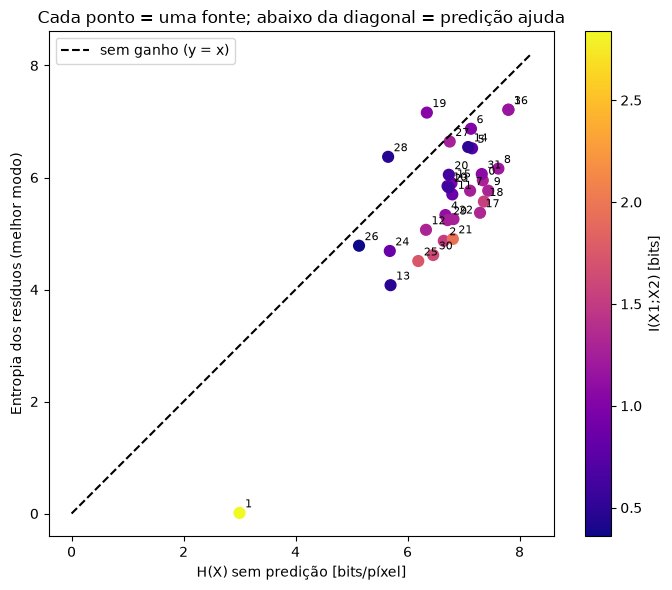

In [16]:
# ---- Gráfico 8: que tipo de algoritmo compensa? ----
# Cada ponto é uma página. Abaixo da diagonal: a predição ajuda.
# Perto ou acima da diagonal: a predição não ajuda.
# A cor é a informação mútua (dependência entre vizinhos).
plt.figure(figsize=(7, 6))
sc = plt.scatter(H1, Hmelhor, c=Imut, cmap="plasma", s=60)
plt.colorbar(sc, label="I(X1;X2) [bits]")
plt.plot([0, 8.2], [0, 8.2], "k--", label="sem ganho (y = x)")
for p in paginas:
    plt.annotate(str(p), (H1[p], Hmelhor[p]), textcoords="offset points", xytext=(4, 4), fontsize=8)
plt.xlabel("H(X) sem predição [bits/píxel]"); plt.ylabel("Entropia dos resíduos (melhor modo)")
plt.title("Cada ponto = uma fonte; abaixo da diagonal = predição ajuda"); plt.legend()
plt.tight_layout(); plt.show()

In [21]:
# ---- Tabela-resumo ----
# ganho(%) = redução de bits/píxel da predição face a H(X); negativo = a predição piora.
print(f"{'Pág':>3} | {'H(X)':>6} | {'H(X2|X1)':>8} | {'I(X1;X2)':>8} | {'Resíduos':>8} | modo | ganho(%)")
for p in paginas:
    print(f"{p:>3} | {H1[p]:6.3f} | {Hcond[p]:8.3f} | {Imut[p]:8.3f} | {Hmelhor[p]:8.3f} | {melhor_modo[p]:>4} | {100*(H1[p]-Hmelhor[p])/H1[p]:6.1f}")

Pág |   H(X) | H(X2|X1) | I(X1;X2) | Resíduos | modo | ganho(%)
  0 |  7.344 |    6.052 |    1.292 |    5.950 |    6 |   19.0
  1 |  2.999 |    0.162 |    2.838 |    0.011 |    4 |   99.6
  2 |  6.646 |    5.126 |    1.521 |    4.869 |    7 |   26.7
  3 |  7.801 |    6.613 |    1.187 |    7.211 |    6 |    7.6
  4 |  6.676 |    5.555 |    1.121 |    5.330 |    7 |   20.2
  5 |  7.152 |    6.411 |    0.740 |    6.521 |    5 |    8.8
  6 |  7.132 |    6.105 |    1.027 |    6.870 |    6 |    3.7
  7 |  7.117 |    5.860 |    1.257 |    5.765 |    7 |   19.0
  8 |  7.622 |    6.419 |    1.203 |    6.159 |    7 |   19.2
  9 |  7.440 |    6.137 |    1.304 |    5.765 |    6 |   22.5
 10 |  6.714 |    6.063 |    0.651 |    5.847 |    7 |   12.9
 11 |  6.799 |    5.946 |    0.853 |    5.698 |    6 |   16.2
 12 |  6.329 |    5.029 |    1.300 |    5.066 |    7 |   20.0
 13 |  5.696 |    5.218 |    0.478 |    4.077 |    6 |   28.4
 14 |  7.082 |    6.581 |    0.501 |    6.544 |    6 |    7.6
 15 | 

# Conclusões
## 1. A predição ajuda na maioria das páginas, mas não em todas.
Em 28 das 32 páginas reduz a entropia, normalmente 10 a 28%.
Piora em 4 páginas: 02 (−12.8%), 08 (−5.6%), 13 (−11.8%) e 30 (−10.7%).
Nessas páginas, H(X2|X1) é bem menor que H(X) (por exemplo, a página 02 vai de 6.34 para 5.31),
mas os resíduos têm mais entropia que os píxeis originais. Ou seja, há dependência entre vizinhos, mas estes preditores lineares simples não a aproveitam.

## 2. O melhor preditor varia de página para página.
Os modos mais frequentes são o 7 (média de A e B), o 6 e o 5. O modo 7 ganha em cerca de metade das páginas.

## 3. Duas fontes são muito diferentes das outras.
As páginas 20 e 25 têm H(X) ≈ 3 bits e, com predição, descem para 0.12 e 0.01 bits (ganho de 96 a 99.6%). 
São as imagens sintéticas (regiões planas e blocos). Comprimem-se de forma quase total com predição simples.

## 4. A dependência entre vizinhos é generalizada.
A informação mútua é positiva em todas as páginas, tipicamente entre 0.5 e 1.9 bits (e ~2.9 nas sintéticas). 
A página 17 tem a maior dependência entre as naturais (1.95 bits), e H(X2|X1) = 4.86 contra H(X) = 6.81.

## 5. Em termos de compressão, o ganho realista é moderado.
Para as imagens naturais, a melhor entropia de resíduos fica tipicamente entre 4.6 e 7.4 bits, contra 8 bits originais.
Ou seja, uma poupança de 10 a 40% antes de contar o overhead. Fica por isso longe do que se consegue nas imagens sintéticas.